In [91]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [92]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [93]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [94]:
latitude = [30,60]


In [95]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_2.8-FESOM_5_deep_on_summer_2020_dry_spell_30-60N.nc')['__xarray_dataarray_variable__']
ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_2.8-FESOM_5_deep_off_summer_2020_dry_spell_30-60N.nc')['__xarray_dataarray_variable__']
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_cycle3_summer_2020-2024_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_cycle4_summer_1990-2019_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/ICON_zoom10_summer_2020-2024_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/ICON_zoom9_summer_2020-2024_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/CESM2_ens_1850-2014_dry_spell_summer_30-60N.nc')['__xarray_dataarray_variable__']
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IMERG_summer_2014-2023_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
#ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
#ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
#icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
#icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))



In [96]:
print(ifs_on)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 1, value: 9206612)> Size: 37MB
[9206612 values with dtype=int32]
Coordinates:
  * value    (value) int64 74MB 0 1 2 3 4 ... 9206608 9206609 9206610 9206611
    lat      (value) float64 74MB ...
    lon      (value) float64 74MB ...
Dimensions without coordinates: year


In [97]:
print(icon_cycle4)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 5, cell: 574808)> Size: 11MB
[2874040 values with dtype=int32]
Coordinates:
  * cell     (cell) int64 5MB 0 1 2 3 4 5 ... 574803 574804 574805 574806 574807
    lat      (cell) float64 5MB ...
    lon      (cell) float64 5MB ...
Dimensions without coordinates: year


In [98]:
print(ifs_cycle4.lat.values.max())

59.961687104591476


In [99]:
print(icon_cycle3)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 5, cell: 2299980)> Size: 46MB
[11499900 values with dtype=int32]
Coordinates:
  * cell     (cell) int64 18MB 0 1 2 3 4 ... 2299976 2299977 2299978 2299979
    lat      (cell) float64 18MB ...
    lon      (cell) float64 18MB ...
Dimensions without coordinates: year


In [100]:
land_sea_ifs_high = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/ifs_hpx2048_lsm_30-60N.nc')['lsm']
land_sea_ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
land_sea_icon_zoom10 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
land_sea_imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
land_sea_imerg = land_sea_imerg.assign_coords(lat=imerg.lat, lon=imerg.lon)
land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2.lat, lon=cesm2.lon)

ifs_on_land = ifs_on.where(land_sea_ifs_high > 0, np.nan)
ifs_off_land = ifs_off.where(land_sea_ifs_high > 0, np.nan)
ifs_cycle3_land = ifs_cycle3.where(land_sea_ifs_cycle3 > 0, np.nan)
ifs_cycle4_land = ifs_cycle4.where(land_sea_ifs_zoom9 > 0, np.nan)
icon_cycle3_land = icon_cycle3.where(land_sea_icon_zoom10 < 1, np.nan)
icon_cycle4_land = icon_cycle4.where(land_sea_icon_zoom9 < 1, np.nan)
imerg_land = imerg.where(land_sea_imerg < 100, np.nan)

cesm2_land = cesm2.where(land_sea_cesm2 > 0, np.nan)


In [101]:
imerg_land_mean = imerg_land.mean(dim=['lat','lon'])

In [102]:
print(imerg_land_mean.std())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(1.40359334)


In [103]:
print(imerg_land_mean.mean())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(30.74678568)


In [104]:
ifs_cycle4_land_mean = ifs_cycle4_land.mean(dim=['value'])

In [105]:
print(ifs_cycle4_land_mean.std())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(2.02737436)


In [106]:
print(ifs_cycle4_land_mean.mean())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(44.32961225)


In [107]:
cesm2_land_mean = cesm2_land[9,:,:].mean(dim=['lat','lon'])

In [108]:
print(cesm2_land_mean.mean())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(31.08351937)
Coordinates:
    time     object 8B 2017-01-01 00:00:00


In [109]:
ifs_on_land = ifs_on_land.stack(sample=("year", "value"))
ifs_off_land = ifs_off_land.stack(sample=("year", "value"))
ifs_cycle3_land = ifs_cycle3_land.stack(sample=("year", "value"))
ifs_cycle4_land = ifs_cycle4_land.stack(sample=("year", "value"))
icon_cycle3_land = icon_cycle3_land.stack(sample=("year", "cell"))
icon_cycle4_land = icon_cycle4_land.stack(sample=("year", "cell"))
imerg_land = imerg_land.stack(sample=("year", "lat", "lon"))
cesm2_land = cesm2_land.stack(sample=("member", "year", "lat", "lon"))

In [110]:
ifs_on_land = ifs_on_land.where(~ifs_on_land.isnull(), drop=True)
ifs_off_land = ifs_off_land.where(~ifs_off_land.isnull(), drop=True)
ifs_cycle3_land = ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)
ifs_cycle4_land = ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)
icon_cycle3_land = icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)
icon_cycle4_land = icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)
imerg_land = imerg_land.where(~imerg_land.isnull(), drop=True)
cesm2_land = cesm2_land.where(~cesm2_land.isnull(), drop=True)


In [111]:
#For IMERG weighting
# 1D cos(lat) weights
lat_rad = np.deg2rad(imerg.lat)
coslat = np.cos(lat_rad)                   # dims: ['lat']

w_lat = xr.DataArray(
    coslat,
    dims=['lat'],
    coords={'lat': imerg.lat}
)

# Broadcast to (lat, lon)
w_imerg_2d = w_lat.broadcast_like(land_sea_imerg)
# Mask to land only (same land mask you use for imerg_land)
w_imerg_2d = w_imerg_2d.where(land_sea_imerg < 100)
#w_imerg_2d = w_imerg_2d / w_imerg_2d.sum()
# Broadcast spatial weights to (year, lat, lon):
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_imerg_2d.values, imerg.shape),
    dims=imerg.dims,
    coords=imerg.coords,
)
w_imerg_land = w_imerg_full.where(land_sea_imerg < 100, np.nan)

# Stack in exactly the same way as imerg_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))

# Drop weights where the data is NaN to keep alignment
w_imerg_land = w_imerg_land.where(~imerg_land.isnull(), drop=True)
x_imerg = imerg_land.values.ravel()
w_imerg = w_imerg_land.values.ravel()


In [112]:
print(w_imerg_2d.sum())

<xarray.DataArray 'lat' ()> Size: 4B
array(396037.75, dtype=float32)


In [113]:
# 1D cos(lat) for CESM2
lat_rad_cesm2 = np.deg2rad(cesm2.lat)
coslat_cesm2 = np.cos(lat_rad_cesm2)

w_lat_cesm2 = xr.DataArray(
    coslat_cesm2,
    dims=['lat'],
    coords={'lat': cesm2.lat}
)

# Broadcast to (lat, lon) on CESM2 land mask
w_cesm2_2d = w_lat_cesm2.broadcast_like(land_sea_cesm2)
w_cesm2_2d = w_cesm2_2d.where(land_sea_cesm2 > 0)

# Broadcast to full CESM2(domain: member, year, lat, lon)
w_cesm2_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, cesm2.shape),
    dims=cesm2.dims,
    coords=cesm2.coords,
)

w_cesm2_land = w_cesm2_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_cesm2_land = w_cesm2_land.stack(sample=("member", "year", "lat", "lon"))

# Align mask with data
w_cesm2_land = w_cesm2_land.where(~cesm2_land.isnull(), drop=True)

x_cesm2 = cesm2_land.values.ravel()
w_cesm2 = w_cesm2_land.values.ravel()


2026-06-19 17:28:22,942 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2026-06-19 17:28:23,324 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)
2026-06-19 17:28:23,766 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)
2026-06-19 17:28:24,258 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)
2026-06-19 17:28:24,838 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)
2026-06-19 17:28:25,513 - distributed.utils_perf - WARNING - full garbage collections took 13% CPU time recently (threshold: 10%)
2026-06-19 17:28:26,313 - distributed.utils_perf - WARNING - full garbage collections took 13% CPU time recently (threshold: 10%)


In [114]:
print(np.median(imerg_land))


19.0


In [115]:
print(np.median(cesm2_land))

17.0


In [116]:
print(np.median(ifs_off_land))

22.0


In [117]:
print(np.median(ifs_on_land))

23.0


In [118]:
print(np.median(icon_cycle4_land))

20.0


In [119]:
print(np.median(icon_cycle3_land))

25.0


In [120]:
print(np.median(ifs_cycle3_land))

23.0


In [121]:
print(np.median(ifs_cycle4_land))

22.0


In [122]:
print(np.quantile(ifs_on_land,0.95))

180.0


In [123]:
print(np.quantile(ifs_off_land,0.95))

175.0


In [124]:
print(np.quantile(ifs_cycle3_land,0.95))

171.0


In [125]:
print(np.quantile(ifs_cycle4_land,0.95))

175.0


In [126]:
print(np.quantile(icon_cycle3_land,0.95))

164.0


In [130]:
print(np.quantile(icon_cycle4_land,0.95))

165.0


In [128]:
print(np.quantile(cesm2_land,0.95))

130.0


In [131]:
print(np.quantile(imerg_land,0.95))

107.0


In [139]:
print(imerg_land)

<xarray.DataArray '__xarray_dataarray_variable__' (sample: 5766530)> Size: 46MB
array([94., 94., 94., ..., 27., 27., 22.])
Coordinates:
  * sample   (sample) object 46MB MultiIndex
  * year     (sample) int64 46MB 0 0 0 0 0 0 0 0 0 0 0 ... 9 9 9 9 9 9 9 9 9 9 9
  * lat      (sample) float32 23MB 30.05 30.05 30.05 30.05 ... 59.95 59.95 59.95
  * lon      (sample) float32 23MB -115.8 -115.8 -115.6 ... 170.3 170.4 170.6


In [141]:
print(ifs_on_land)

<xarray.DataArray '__xarray_dataarray_variable__' (sample: 4697561)> Size: 38MB
array([107., 172., 172., ...,  16.,  16.,  16.])
Coordinates:
    lat      (sample) float64 38MB 30.02 30.02 30.02 30.04 ... 41.76 41.76 41.79
    lon      (sample) float64 38MB 56.21 56.12 56.16 56.18 ... 270.0 270.0 270.0
  * sample   (sample) object 38MB MultiIndex
  * year     (sample) int64 38MB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * value    (sample) int64 38MB 0 1 2 3 4 ... 9206608 9206609 9206610 9206611


In [133]:
print(icon_cycle4_land.max())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(184.)


In [135]:
print(cesm2.max())

<xarray.DataArray '__xarray_dataarray_variable__' ()> Size: 8B
array(184.)


In [142]:
mask = (ifs_on_land == 184) 
percentage = (mask.sum() / ifs_on_land.size) * 100
print(f"Percentage equal to 184: {percentage.values:.2f}%")

Percentage equal to 184: 4.38%


In [143]:
mask = (ifs_off_land == 184)
percentage = (mask.sum() / ifs_off_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 3.87%


In [144]:
mask = (ifs_cycle3_land == 184)
percentage = (mask.sum() / ifs_cycle3_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 2.96%


In [145]:
mask = (ifs_cycle4_land == 184)
percentage = (mask.sum() / ifs_cycle4_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 3.77%


In [146]:
mask = (icon_cycle3_land == 184)
percentage = (mask.sum() / icon_cycle3_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 2.75%


In [147]:
mask = (icon_cycle4_land == 184)
percentage = (mask.sum() / icon_cycle4_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 2.65%


In [148]:
mask = (cesm2_land == 184)
percentage = (mask.sum() / cesm2_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 0.09%


In [149]:
mask = (imerg == 184)
percentage = (mask.sum() / imerg.size) * 100
print(f"Percentage equal to 184: {percentage.values:.2f}%")

Percentage equal to 184: 0.30%


In [159]:
mask = (ifs_on_land > 60) & (ifs_on_land < 185)
percentage = (mask.sum() / ifs_on_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 22.41%


In [160]:
mask = (ifs_off_land > 60) & (ifs_off_land < 185)
percentage = (mask.sum() / ifs_off_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 20.84%


In [161]:
mask = (ifs_cycle3_land > 60) & (ifs_cycle3_land < 185)
percentage = (mask.sum() / ifs_cycle3_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 21.48%


In [162]:
mask = (ifs_cycle4_land > 60) & (ifs_cycle4_land < 185)
percentage = (mask.sum() / ifs_cycle4_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 21.47%


In [163]:
mask = (icon_cycle3_land > 60) & (icon_cycle3_land < 185)
percentage = (mask.sum() / icon_cycle3_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 20.66%


In [164]:
mask = (icon_cycle4_land > 60) & (icon_cycle4_land < 185)
percentage = (mask.sum() / icon_cycle4_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 17.79%


In [165]:
mask = (cesm2_land > 60) & (cesm2_land < 185)
percentage = (mask.sum() / cesm2_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 12.66%


In [168]:
mask = (imerg_land > 60) & (imerg_land < 185)
percentage = (mask.sum() / imerg_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 10.57%


In [170]:
# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)

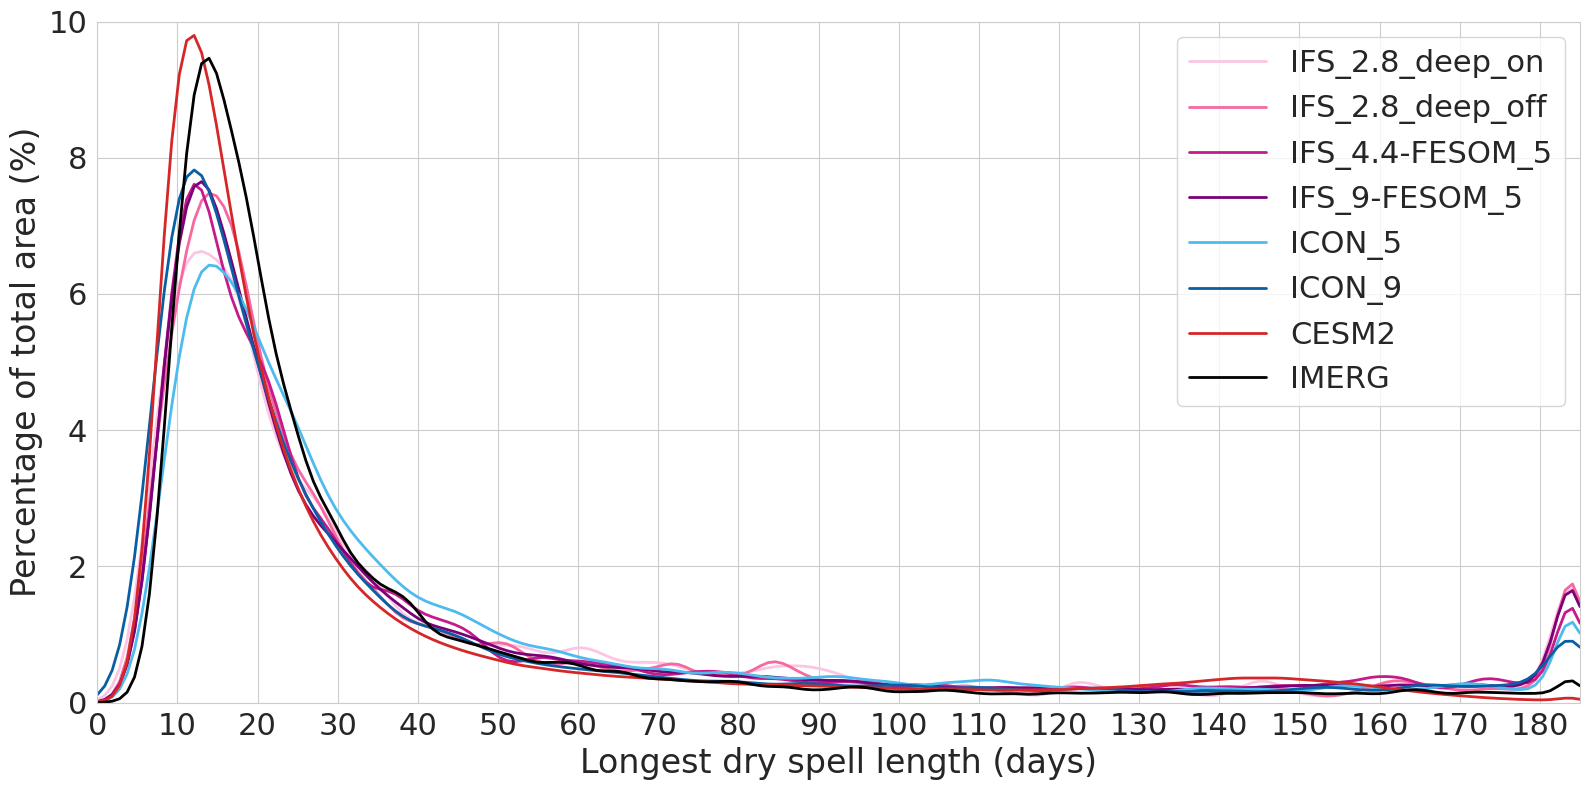

In [17]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 185


bin_width  = 2.0






datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land,       ones_like_da(ifs_on_land),       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land,      ones_like_da(ifs_off_land),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land,   ones_like_da(ifs_cycle3_land),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land,   ones_like_da(ifs_cycle4_land),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land,  ones_like_da(icon_cycle3_land),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land,  ones_like_da(icon_cycle4_land),  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land,        w_cesm2_land,                    '#D62728', 'CESM2'),
    (imerg_land,        w_imerg_land,                    '#000000',       'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Longest dry spell length (days)'
ax.set_ylim(0, 10)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 10)
ax.set_xticks(xticks)
# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 22},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_dry_spell_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()

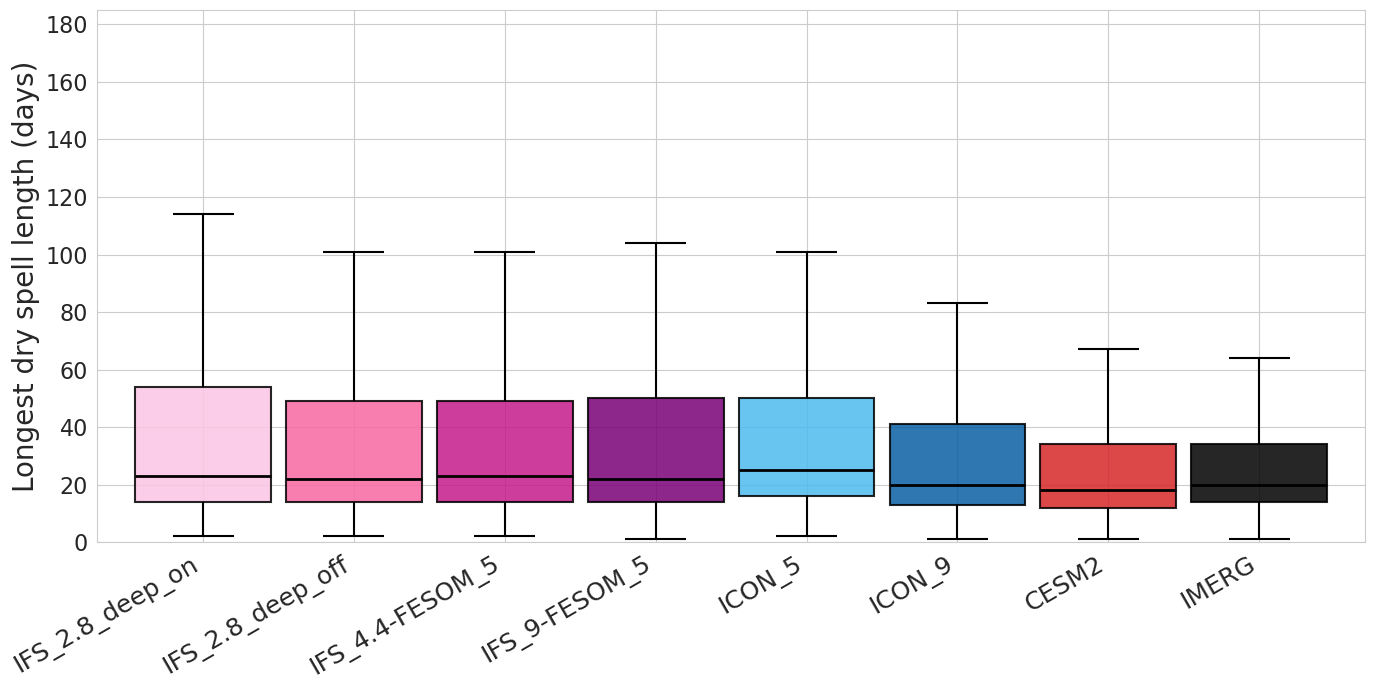

In [172]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# ── weighted quantile helper ──────────────────────────────────────────────────
def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w)
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)

# ── datasets: IFS/ICON use uniform weights, CESM2/IMERG use cos(lat) ─────────
datasets = [
    (ifs_on_land,      ones_like_da(ifs_on_land),      '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land,     ones_like_da(ifs_off_land),     '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land,  ones_like_da(ifs_cycle3_land),  '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land,  ones_like_da(ifs_cycle4_land),  '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land, ones_like_da(icon_cycle3_land), '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land, ones_like_da(icon_cycle4_land), '#0A5FA3', 'ICON_9'),
    (cesm2_land,       w_cesm2_land,                   '#D62728', 'CESM2'),
    (imerg_land,       w_imerg_land,                   '#000000', 'IMERG'),
]

# ── collect stats ─────────────────────────────────────────────────────────────
labels, colors, stats = [], [], []

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel().astype(float)
    w = wts_da.values.ravel().astype(float)

    # drop NaNs (uniform-weight arrays have no NaNs, but guard anyway)
    mask = np.isfinite(x) & np.isfinite(w)
    x, w = x[mask], w[mask]

    q25, q50, q75 = weighted_quantile(x, w, [0.25, 0.50, 0.75])
    iqr       = q75 - q25
    lo_whisk  = x[x >= q25 - 1.5 * iqr].min()
    hi_whisk  = x[x <= q75 + 1.5 * iqr].max()
    mean      = np.average(x, weights=w)

    labels.append(label)
    colors.append(color)
    stats.append(dict(q25=q25, q50=q50, q75=q75,
                      lo=lo_whisk, hi=hi_whisk, mean=mean))

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
sns.set_style("whitegrid")

n   = len(stats)
pos = np.arange(1, n + 1)
bw  = 0.45

for p, s, c in zip(pos, stats, colors):
    # IQR box
    rect = mpatches.FancyBboxPatch(
        (p - bw, s['q25']), 2 * bw, s['q75'] - s['q25'],
        boxstyle="square,pad=0", linewidth=1.5,
        edgecolor='k', facecolor=c, alpha=0.85, zorder=3
    )
    ax.add_patch(rect)

    # median line
    ax.hlines(s['q50'], p - bw, p + bw, colors='k', linewidth=2.0, zorder=4)

    # whiskers
    ax.vlines(p, s['lo'],  s['q25'], colors='k', linewidth=1.5, zorder=2)
    ax.vlines(p, s['q75'], s['hi'],  colors='k', linewidth=1.5, zorder=2)

    # whisker caps
    cap_hw = bw * 0.45
    ax.hlines(s['lo'], p - cap_hw, p + cap_hw, colors='k', linewidth=1.5, zorder=2)
    ax.hlines(s['hi'], p - cap_hw, p + cap_hw, colors='k', linewidth=1.5, zorder=2)

    # weighted mean diamond
    #ax.plot(p, s['mean'], marker='D', color='white',
      #      markeredgecolor='k', markersize=7, zorder=5)

# ── axes formatting ───────────────────────────────────────────────────────────
ax.set_xlim(0.3, n + 0.7)
ax.set_ylim(0, 185)
ax.set_xticks(pos)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=18)
ax.set_ylabel('Longest dry spell length (days)', fontsize=20)
ax.set_yticks(np.arange(0, 190, 20))
ax.tick_params(axis='y', labelsize=16)

# ── legend ────────────────────────────────────────────────────────────────────
legend_elements = [
    Line2D([0], [0], color='k', linewidth=2,                           label='Median'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='white',
           markeredgecolor='k', markersize=8,                          label='Weighted mean'),
    mpatches.Patch(facecolor='grey', edgecolor='k', alpha=0.85,        label='IQR (25–75 %)'),
    Line2D([0], [0], color='k', linewidth=1.5,                         label='Whiskers (1.5 × IQR)'),
]
#ax.legend(handles=legend_elements, loc='upper right', fontsize=13, framealpha=0.9)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_dry_spell_boxplot.pdf',
            format='pdf', bbox_inches='tight')
plt.show()